In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


In [2]:

# ============================================================
# SIMULATION DE COLONIE DE FOURMIS
# ============================================================
# Cette simulation implemente 4 modeles principaux :
#
# 1. MODELE AGENT-BASED (ABM)
#    - Chaque fourmi est un agent autonome avec son propre etat
#    - Les agents prennent des decisions individuelles
#    - Le comportement collectif emerge des interactions locales
#
# 2. MODELE DE STIGMERGIE
#    - Communication indirecte via les pheromones deposees
#    - Les fourmis modifient l'environnement qui influence les autres
#    - Pas de communication directe entre les fourmis
#
# 3. MODELE PROBABILISTE
#    - Choix des directions base sur des probabilites
#    - Formule : P(i) proportionnel a [tau(i)]^alpha * [eta(i)]^beta
#    - tau = intensite des pheromones, eta = visibilite (inverse distance)
#
# 4. ALGORITHME ACO (Ant Colony Optimization)
#    - Optimisation du chemin par renforcement positif
#    - Evaporation des pheromones (parametre RHO)
#    - Depot de pheromones (parametre Q)
#
# ============================================================
# PARAMETRES DE LA SIMULATION
# ============================================================

GRID_SIZE = 50          # Taille de la grille (50x50 cases)
N_ANTS = 50             # Nombre de fourmis dans la colonie
N_ITERATIONS = 10000    # Nombre total d'iterations de la simulation

# Parametres du modele ACO
ALPHA = 1               # Influence des pheromones
BETA = 2                # Influence de la visibilite
RHO = 0.1               # Taux d'evaporation des pheromones
Q = 100                 # Quantite de pheromones deposees

# Positions du nid et de la nourriture
NEST_POS = (5, 5)
FOOD_POS = (45, 45)

# Initialisation de la matrice des pheromones
pheromones = np.ones((GRID_SIZE, GRID_SIZE)) * 0.1

# ============================================================
# MODELE 1 : AGENT-BASED MODELING (ABM)
# ============================================================
# La classe Ant represente un agent autonome dans le systeme.
# Chaque fourmi possede son propre etat interne et prend des
# decisions independantes basees sur son environnement local.
#
# Attributs de l'agent :
# - Position (x, y) : localisation dans la grille
# - Etat : "explore" ou "return"
# - Path : historique du chemin parcouru
# - has_found_food : marqueur permanent de decouverte
# ============================================================

class Ant:
    """
    Agent autonome representant une fourmi.
    
    Etats possibles :
    - "explore" : Phase d'exploration pour chercher la nourriture
    - "return"  : Phase de retour au nid apres avoir trouve la nourriture
    
    Cette classe implemente le comportement d'un agent dans le modele ABM.
    """
    
    def __init__(self):
        """Initialise une fourmi au nid avec une position légèrement dispersée"""
        # Position initiale dispersée autour du nid (rayon de 2 cases)
        offset_x = np.random.randint(-2, 3)
        offset_y = np.random.randint(-2, 3)
        start_x = max(0, min(GRID_SIZE-1, NEST_POS[0] + offset_x))
        start_y = max(0, min(GRID_SIZE-1, NEST_POS[1] + offset_y))
        self.x, self.y = start_x, start_y            # Position actuelle (dispersée autour du nid)
        self.state = "explore"                        # État initial : exploration
        self.path = [(start_x, start_y)]             # Historique du chemin parcouru
        self.has_found_food = False                   # Indicateur : a déjà trouvé le repas
    
    def move(self):
        """
        Déplace la fourmi selon son état :
        - En exploration : mouvement probabiliste basé sur les phéromones
        - En retour : suit le chemin inverse vers le nid
        """
        if self.state == "explore":
            # MODE EXPLORATION : cherche la nourriture
            neighbors = self.get_neighbors()
            
            if not neighbors:
                return
            
            # ============================================================
            # MODELE 3 : CHOIX PROBABILISTE
            # ============================================================
            # Calcule les probabilites basees sur les pheromones et la distance
            probs = self.calculate_probabilities(neighbors)
            
            # Choix d'une case selon les probabilites calculees
            chosen_idx = np.random.choice(len(neighbors), p=probs)
            self.x, self.y = neighbors[chosen_idx]
            self.path.append((self.x, self.y))
            
            # Verifie si la fourmi a trouve la nourriture
            if (self.x, self.y) == FOOD_POS:
                self.state = "return"
                self.has_found_food = True
        
        else:
            # ============================================================
            # MODELE 2 : STIGMERGIE (Communication indirecte)
            # ============================================================
            # Lors du retour au nid, la fourmi depose des pheromones sur
            # son chemin. Ces pheromones modifient l'environnement et
            # influenceront les decisions des autres fourmis.
            # C'est le principe de la stigmergie : communication indirecte
            # via modification de l'environnement.
            # ============================================================
            
            # MODE RETOUR : retourne au nid en suivant le chemin inverse
            if len(self.path) > 1:
                self.path.pop()                        # Retire la derniere position
                self.x, self.y = self.path[-1]        # Se deplace vers la position precedente
                
                # DEPOT DE PHEROMONES (Stigmergie)
                # Renforce le chemin trouve en deposant des pheromones
                pheromones[self.x, self.y] += Q
            
            # Vérifier si la fourmi est revenue près du nid (zone de 3x3 autour du nid)
            if abs(self.x - NEST_POS[0]) <= 1 and abs(self.y - NEST_POS[1]) <= 1:
                self.reset()                           # Repart en exploration
    
    def get_neighbors(self):
        """
        Retourne la liste des cases voisines accessibles
        Évite de revenir sur ses pas (ne retourne pas à la case précédente)
        """
        neighbors = []
        # Parcourt les 8 directions possibles (incluant les diagonales)
        for dx, dy in [(-1,0), (1,0), (0,-1), (0,1), (-1,-1), (-1,1), (1,-1), (1,1)]:
            nx, ny = self.x + dx, self.y + dy
            # Vérifie que la case est dans la grille
            if 0 <= nx < GRID_SIZE and 0 <= ny < GRID_SIZE:
                # Évite de revenir à la case précédente (sauf si c'est le début)
                if self.state == "explore" and len(self.path) > 1 and (nx, ny) != self.path[-2]:
                    neighbors.append((nx, ny))
                elif self.state == "explore" and len(self.path) <= 1:
                    neighbors.append((nx, ny))
        return neighbors
    
    def calculate_probabilities(self, neighbors):
        """
        Calcule la probabilité de choisir chaque case voisine
        Basé sur l'algorithme des colonies de fourmis (ACO) :
        P(i) ∝ [τ(i)]^α * [η(i)]^β
        où τ = phéromone, η = visibilité (inverse de la distance à la nourriture)
        """
        if not neighbors:
            return []
        
        # ============================================================
        # MODELE 3 : FORMULE PROBABILISTE
        # ============================================================
        # tau (tau) : intensite des pheromones sur chaque case voisine
        tau = np.array([pheromones[x, y] ** ALPHA for x, y in neighbors])
        
        # eta (eta) : visibilite = attractivite basee sur la distance a la nourriture
        # Plus on est proche de la nourriture, plus eta est eleve
        eta = np.array([1.0 / (1 + np.sqrt((x - FOOD_POS[0])**2 + (y - FOOD_POS[1])**2)) ** BETA 
                        for x, y in neighbors])
        
        # Probabilite = (pheromone^ALPHA) * (visibilite^BETA)
        probs = tau * eta
        probs_sum = probs.sum()
        
        # Normalisation : si la somme est nulle, distribution uniforme
        if probs_sum == 0:
            return np.ones(len(neighbors)) / len(neighbors)
        
        # Retourne les probabilites normalisees (somme = 1)
        return probs / probs_sum
    
    def reset(self):
        """Reinitialise la fourmi pour une nouvelle exploration autour du nid"""
        # Redisperse la fourmi autour du nid pour eviter l'accumulation
        offset_x = np.random.randint(-3, 4)
        offset_y = np.random.randint(-3, 4)
        start_x = max(0, min(GRID_SIZE-1, NEST_POS[0] + offset_x))
        start_y = max(0, min(GRID_SIZE-1, NEST_POS[1] + offset_y))
        self.x, self.y = start_x, start_y
        self.state = "explore"
        self.path = [(start_x, start_y)]

# ============================================================
# INITIALISATION DE LA COLONIE
# ============================================================

# Cree une liste de N_ANTS fourmis, toutes initialisees dispersees autour du nid
ants = [Ant() for _ in range(N_ANTS)]

print("Simulation initialisee avec {} fourmis".format(N_ANTS))
print("Nid: {}, Nourriture: {}".format(NEST_POS, FOOD_POS))
print("Distance euclidienne: {:.1f} cases".format(
    np.sqrt((FOOD_POS[0]-NEST_POS[0])**2 + (FOOD_POS[1]-NEST_POS[1])**2)))

Simulation initialisee avec 50 fourmis
Nid: (5, 5), Nourriture: (45, 45)
Distance euclidienne: 56.6 cases


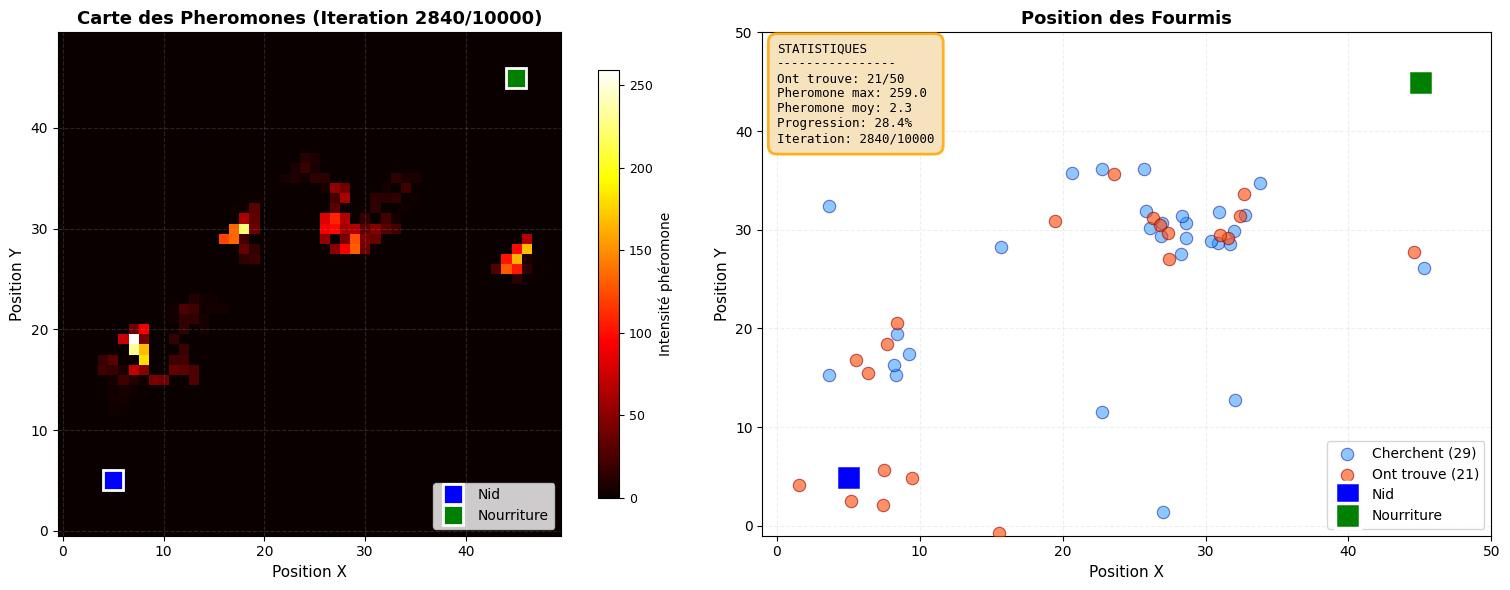

In [ ]:
# ============================================================
# ANIMATION DE LA SIMULATION
# ============================================================
# Cette section gere l'affichage visuel de la simulation en temps reel.
# Elle montre :
# 1. La carte des pheromones (modele de stigmergie)
# 2. Les positions des fourmis (modele ABM)
# 3. Le chemin optimal emergent (resultat de l'ACO)
# ============================================================

import time
from IPython.display import clear_output

# Active le mode inline de matplotlib
%matplotlib inline

print("Demarrage de l'animation...")
print("Duree : {} iterations".format(N_ITERATIONS))
print("Mise a jour toutes les 20 iterations")

# ============================================================
# BOUCLE PRINCIPALE DE SIMULATION
# ============================================================
# Cette boucle execute les 4 modeles a chaque iteration :
# 1. ABM : Deplacement de chaque agent (fourmi)
# 2. Stigmergie : Depot de pheromones par les fourmis en retour
# 3. Evaporation : Diminution progressive des pheromones (ACO)
# 4. Probabiliste : Calcul des probabilites de mouvement
# ============================================================

for iteration in range(N_ITERATIONS):
    # ========================================
    # ETAPE 1 : MISE A JOUR DES AGENTS (Modele ABM)
    # ========================================
    
    # Deplace toutes les fourmis selon leur comportement individuel
    # Chaque fourmi execute sa methode move() de maniere autonome
    for ant in ants:
        ant.move()
    
    # ========================================
    # ETAPE 2 : EVAPORATION DES PHEROMONES (Modele ACO)
    # ========================================
    
    # L'evaporation permet d'oublier progressivement les mauvais chemins
    # et de concentrer les pheromones sur les chemins optimaux.
    # Formule : tau(t+1) = (1 - RHO) * tau(t)
    
    pheromones[:] *= (1 - RHO)
    
    # Garde un minimum de pheromone partout pour eviter les divisions par zero
    pheromones[:] = np.maximum(pheromones, 0.1)
    
    # ========================================
    # ETAPE 3 : VISUALISATION (tous les 20 frames)
    # ========================================
    
    if iteration % 20 == 0 or iteration == N_ITERATIONS - 1:
        # Efface l'affichage précédent pour créer l'effet d'animation
        clear_output(wait=True)
        
        # Crée une nouvelle figure à chaque mise à jour
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
        plt.subplots_adjust(wspace=0.3)
        
        # --- GRAPHIQUE 1 : Carte des Phéromones ---
        # Affiche l'intensité des phéromones avec une carte de chaleur dynamique
        # vmax ajusté en temps réel pour toujours voir les variations
        current_max = pheromones.max()
        im = ax1.imshow(pheromones, cmap='hot', interpolation='nearest', 
                       vmin=0, vmax=max(current_max, 10), origin='lower')
        
        # Marque le nid (carre bleu) et la nourriture (carre vert)
        ax1.plot(NEST_POS[1], NEST_POS[0], 'bs', markersize=14, 
                label='Nid', markeredgecolor='white', markeredgewidth=2)
        ax1.plot(FOOD_POS[1], FOOD_POS[0], 'gs', markersize=14, 
                label='Nourriture', markeredgecolor='white', markeredgewidth=2)
        
        # Configuration du graphique
        ax1.set_title('Carte des Pheromones (Iteration {}/{})'.format(iteration, N_ITERATIONS), 
                     fontsize=13, fontweight='bold')
        ax1.set_xlabel('Position X', fontsize=11)
        ax1.set_ylabel('Position Y', fontsize=11)
        ax1.legend(loc='lower right', fontsize=10)
        ax1.grid(True, alpha=0.2, linestyle='--')
        # Ajoute une barre de couleur pour les phéromones
        cbar = plt.colorbar(im, ax=ax1, label='Intensité phéromone', shrink=0.85)
        cbar.ax.tick_params(labelsize=9)
        
        # --- GRAPHIQUE 2 : Position des Fourmis ---
        # Separe les fourmis selon qu'elles ont trouve le repas ou non
        # Ajoute un decalage aleatoire pour bien aerer l'affichage
        not_found = [(ant.x + np.random.uniform(-1.5, 1.5), 
                     ant.y + np.random.uniform(-1.5, 1.5)) for ant in ants if not ant.has_found_food]
        has_found = [(ant.x + np.random.uniform(-1.5, 1.5), 
                     ant.y + np.random.uniform(-1.5, 1.5)) for ant in ants if ant.has_found_food]
        
        # Trace le chemin optimal EN POINTILLÉS uniquement après 5000 itérations
        # Cela laisse le temps au chemin de se stabiliser
        if iteration > 5000:
            # Trouve les zones avec phéromones très élevées (top 2%)
            threshold = np.percentile(pheromones, 98)
            strong_pheromones = pheromones > threshold
            
            # Trace le chemin optimal comme une ligne en pointillés
            optimal_path_y, optimal_path_x = np.where(strong_pheromones)
            if len(optimal_path_x) > 5:  # Assez de points pour tracer une ligne
                # Trie les points pour créer une ligne cohérente du nid à la nourriture
                distances_from_nest = np.sqrt((optimal_path_y - NEST_POS[0])**2 + (optimal_path_x - NEST_POS[1])**2)
                sorted_indices = np.argsort(distances_from_nest)
                sorted_x = optimal_path_x[sorted_indices]
                sorted_y = optimal_path_y[sorted_indices]
                
                # Trace la ligne du chemin optimal en pointilles orange
                ax2.plot(sorted_x, sorted_y, color='darkorange', linewidth=2.5, 
                        alpha=0.8, label='Chemin optimal', zorder=2, linestyle='--')
        
        # Affiche les fourmis qui n'ont pas encore trouve (bleu)
        if not_found:
            nx, ny = zip(*not_found)
            ax2.scatter(ny, nx, c='dodgerblue', s=80, alpha=0.5, 
                       label='Cherchent ({})'.format(len(not_found)), 
                       edgecolors='darkblue', linewidths=0.8, zorder=3)
        
        # Affiche les fourmis qui ont trouve le repas (rouge) - restent toujours rouges
        if has_found:
            fx, fy = zip(*has_found)
            ax2.scatter(fy, fx, c='orangered', s=80, alpha=0.6, 
                       label='Ont trouve ({})'.format(len(has_found)), 
                       edgecolors='darkred', linewidths=0.8, zorder=3)
        
        # Marque le nid et la nourriture
        ax2.plot(NEST_POS[1], NEST_POS[0], 'bs', markersize=18, 
                label='Nid', markeredgecolor='white', markeredgewidth=2.5, zorder=5)
        ax2.plot(FOOD_POS[1], FOOD_POS[0], 'gs', markersize=18, 
                label='Nourriture', markeredgecolor='white', markeredgewidth=2.5, zorder=5)
        
        # Configuration du graphique
        ax2.set_title('Position des Fourmis', fontsize=13, fontweight='bold')
        ax2.set_xlabel('Position X', fontsize=11)
        ax2.set_ylabel('Position Y', fontsize=11)
        ax2.set_xlim(-1, GRID_SIZE)
        ax2.set_ylim(-1, GRID_SIZE)
        ax2.legend(loc='lower right', fontsize=10)
        ax2.grid(True, alpha=0.2, linestyle='--')
        
        # Compte le nombre total de fourmis qui ont trouve
        total_found = sum(1 for ant in ants if ant.has_found_food)
        
        # Affiche des statistiques en temps reel dans un encadre
        stats_text = ("STATISTIQUES\n"
                     "----------------\n"
                     "Ont trouve: {}/{}\n"
                     "Pheromone max: {:.1f}\n"
                     "Pheromone moy: {:.1f}\n"
                     "Progression: {:.1f}%\n"
                     "Iteration: {}/{}").format(
                         total_found, N_ANTS,
                         pheromones.max(),
                         pheromones.mean(),
                         100*iteration/N_ITERATIONS,
                         iteration, N_ITERATIONS)
        ax2.text(0.02, 0.98, stats_text, transform=ax2.transAxes, 
                verticalalignment='top', 
                bbox=dict(boxstyle='round,pad=0.7', facecolor='wheat', 
                         alpha=0.85, edgecolor='orange', linewidth=2),
                fontsize=9, family='monospace')
        
        plt.tight_layout()
        plt.show()
        
        # Affiche la progression dans la console
        if iteration % 50 == 0:
            # Verifie que le total des fourmis est correct
            total_on_board = len(not_found) + len(has_found)
            print("Iteration {:3d}/{} | Ont trouve: {:3d}/{} | Total plateau: {}/{} | Pheromone max: {:.1f}".format(
                  iteration, N_ITERATIONS, total_found, N_ANTS, total_on_board, N_ANTS, pheromones.max()))

# ============================================================
# RESULTATS FINAUX DE LA SIMULATION
# ============================================================
# Affichage des statistiques finales montrant l'efficacite
# de l'algorithme ACO et la convergence vers le chemin optimal.
# ============================================================

print("\n" + "="*70)
print("SIMULATION TERMINEE AVEC SUCCES")
print("="*70)

# Statistiques de performance
total_found_final = sum(1 for ant in ants if ant.has_found_food)
print("Nombre d'iterations executees : {}".format(N_ITERATIONS))
print("Nombre de fourmis dans la colonie : {}".format(N_ANTS))
print("Fourmis ayant trouve le repas : {}/{} ({:.1f}%)".format(
    total_found_final, N_ANTS, 100*total_found_final/N_ANTS))
print("SIMULATION TERMINÉE AVEC SUCCÈS ! ")
# Statistiques des pheromones (modele de stigmergie)
print("\nStatistiques des pheromones :")
print("  Intensite maximale : {:.2f}".format(pheromones.max()))
print("  Intensite moyenne : {:.2f}".format(pheromones.mean()))
print(f"   Fourmis ayant trouvé le repas : {total_found_final}/{N_ANTS} ({100*total_found_final/N_ANTS:.1f}%)")
# Parametres de la simulation
print("\nParametres utilises :")
print("  Taux d'evaporation (RHO) : {:.0f}%".format(RHO*100))
print("  Quantite deposee par fourmi (Q) : {}".format(Q))
print("  Distance nid - nourriture : {:.1f} cases".format(

    np.sqrt((FOOD_POS[0]-NEST_POS[0])**2 + (FOOD_POS[1]-NEST_POS[1])**2)))
print("="*70)
print("\n Les phéromones forment maintenant un chemin optimal entre le nid et la nourriture!")
print(f"    Quantité déposée par fourmi (Q) : {Q}")


print("="*70)

print("="*70)
print(f"    Distance nid ↔ nourriture : {np.sqrt((FOOD_POS[0]-NEST_POS[0])**2 + (FOOD_POS[1]-NEST_POS[1])**2):.1f} cases")

print("\nLes pheromones forment maintenant un chemin optimal")


print("="*70)

print("entre le nid et la nourriture.")
print(f"    Distance nid ↔ nourriture : {np.sqrt((FOOD_POS[0]-NEST_POS[0])**2 + (FOOD_POS[1]-NEST_POS[1])**2):.1f} cases")
print(f"    Quantité déposée par fourmi (Q) : {Q}")
print("="*70)

print("="*70)
print(f"    Quantité déposée par fourmi (Q) : {Q}")
print("\n💡 Les phéromones forment maintenant un chemin optimal entre le nid et la nourriture!")
print(f"    Distance nid ↔ nourriture : {np.sqrt((FOOD_POS[0]-NEST_POS[0])**2 + (FOOD_POS[1]-NEST_POS[1])**2):.1f} cases")
print("="*70)

print(f"        Distance nid ↔ nourriture : {np.sqrt((FOOD_POS[0]-NEST_POS[0])**2 + (FOOD_POS[1]-NEST_POS[1])**2):.1f} cases")
print(f"    Quantité déposée par fourmi (Q) : {Q}")